#Part 1: Language Model Training & Comparison

Setup: Google Drive (Colab) or local folder + paths

In [ ]:
import os, sys
try:                                            # running in Google Colab
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/DSA4213_A1'
except ImportError:                             # running locally (VS Code / Jupyter)
    BASE = os.path.abspath('DSA4213_A1')
print('Working folder:', BASE)
OUT  = f'{BASE}/outputs'
sys.path.append(BASE)
assert os.path.exists(f'{OUT}/data_prep.pkl'), 'Run the data-prep notebook first'

Mounted at /content/drive


In [ ]:
%%writefile {BASE}/lm_utils.py
"""Shared utilities for DSA4213 Assignment 1 (Parts I-III).
Models, batching, training loop, evaluation, timing and text generation.
"""
import math, time, copy, random, re
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

PAD_ID, UNK_ID = 0, 1


def set_seed(s=42):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def sync(device):
    if str(device).startswith('cuda'):
        torch.cuda.synchronize()


#batching
def make_lm_tensors(ids, seq_len=64, pad_id=PAD_ID):
    """Cut a token stream into non-overlapping chunks.
    x = ids[s : s+L], y = ids[s+1 : s+L+1]  ->  every token except the first is a target exactly once.
    The last chunk is right-padded with PAD; PAD targets are ignored in the loss."""
    n = len(ids) - 1
    n_chunks = math.ceil(n / seq_len)
    X = torch.full((n_chunks, seq_len), pad_id, dtype=torch.long)
    Y = torch.full((n_chunks, seq_len), pad_id, dtype=torch.long)
    for c in range(n_chunks):
        s, e = c * seq_len, min(c * seq_len + seq_len, n)
        X[c, :e - s] = torch.tensor(ids[s:e])
        Y[c, :e - s] = torch.tensor(ids[s + 1:e + 1])
    return X, Y


#models
def _init_embedding(emb, emb_weights, freeze):
    if emb_weights is not None:
        emb.weight.data.copy_(torch.as_tensor(emb_weights, dtype=torch.float))
        emb.weight.data[PAD_ID].zero_()
    emb.weight.requires_grad = not freeze


class RecurrentLM(nn.Module):
    """Vanilla RNN (cell='rnn') or LSTM (cell='lstm') language model."""
    def __init__(self, vocab_size, emb_dim=100, hidden=256, layers=2, dropout=0.3,
                 cell='lstm', emb_weights=None, freeze_emb=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        _init_embedding(self.emb, emb_weights, freeze_emb)
        rnn_cls = nn.LSTM if cell == 'lstm' else nn.RNN
        self.rnn = rnn_cls(emb_dim, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, vocab_size)

    def forward(self, x, return_hidden=False):
        h, _ = self.rnn(self.drop(self.emb(x)))          # (B, T, hidden)
        logits = self.out(self.drop(h))
        return (logits, h) if return_hidden else logits


class TransformerLM(nn.Module):
    """Decoder-only Transformer: token emb -> linear to d_model + learned positions -> causal self-attention."""
    def __init__(self, vocab_size, emb_dim=100, d_model=256, nhead=4, layers=2, ff=512,
                 dropout=0.3, max_len=64, emb_weights=None, freeze_emb=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        _init_embedding(self.emb, emb_weights, freeze_emb)
        self.proj = nn.Linear(emb_dim, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff, dropout,
                                           batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(d_model, vocab_size)
        self.max_len = max_len

    def forward(self, x, return_hidden=False):
        T = x.size(1)
        pos = torch.arange(T, device=x.device)
        h = self.drop(self.proj(self.emb(x)) + self.pos(pos))
        mask = torch.triu(torch.full((T, T), float('-inf'), device=x.device), diagonal=1)  # causal
        h = self.norm(self.enc(h, mask=mask, is_causal=True))
        logits = self.out(h)
        return (logits, h) if return_hidden else logits


def build_model(kind, vocab_size, cfg, emb_weights=None, freeze_emb=False):
    if kind in ('rnn', 'lstm'):
        return RecurrentLM(vocab_size, cfg['emb_dim'], cfg['hidden'], cfg['layers'],
                           cfg['dropout'], cell=kind, emb_weights=emb_weights, freeze_emb=freeze_emb)
    if kind == 'transformer':
        return TransformerLM(vocab_size, cfg['emb_dim'], cfg['d_model'], cfg['nhead'], cfg['layers'],
                             cfg['ff'], cfg['dropout'], cfg['seq_len'],
                             emb_weights=emb_weights, freeze_emb=freeze_emb)
    raise ValueError(kind)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# train / evaluate
def run_epoch(model, X, Y, device, opt=None, batch_size=32, clip=1.0):
    """Returns average next-token cross-entropy per (non-PAD) target token."""
    train = opt is not None
    model.train(train)
    order = torch.randperm(len(X)) if train else torch.arange(len(X))
    tot_loss, tot_tok = 0.0, 0
    with torch.set_grad_enabled(train):
        for i in range(0, len(X), batch_size):
            b = order[i:i + batch_size]
            x, y = X[b].to(device), Y[b].to(device)
            logits = model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1),
                                   ignore_index=PAD_ID, reduction='sum')
            n = (y != PAD_ID).sum().item()
            if train:
                opt.zero_grad()
                (loss / n).backward()
                nn.utils.clip_grad_norm_(model.parameters(), clip)
                opt.step()
            tot_loss += loss.item(); tot_tok += n
    return tot_loss / tot_tok


def train_lm(model, Xtr, Ytr, Xva, Yva, device, lr=1e-3, max_epochs=60, patience=3,
             batch_size=32, seed=42, verbose=True):
    """Train with AdamW + early stopping on validation loss. Restores the best-val weights."""
    set_seed(seed)
    model.to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {'train_loss': [], 'val_loss': [], 'epoch_time': []}
    best, best_state, bad = float('inf'), None, 0
    t_start = time.perf_counter()
    for ep in range(1, max_epochs + 1):
        sync(device); t0 = time.perf_counter()
        tr = run_epoch(model, Xtr, Ytr, device, opt, batch_size)
        sync(device); t_ep = time.perf_counter() - t0
        va = run_epoch(model, Xva, Yva, device, None, 256)
        hist['train_loss'].append(tr); hist['val_loss'].append(va); hist['epoch_time'].append(t_ep)
        if verbose:
            print(f'  epoch {ep:2d} | train {tr:.3f} | val {va:.3f} (ppl {math.exp(va):6.1f}) | {t_ep:5.1f}s')
        if va < best - 1e-4:
            best, bad = va, 0
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f'  early stop: no val improvement for {patience} epochs')
                break
    model.load_state_dict(best_state)
    hist['best_epoch'] = int(np.argmin(hist['val_loss'])) + 1
    hist['epochs_run'] = len(hist['val_loss'])
    hist['train_time_s'] = sum(hist['epoch_time'])
    hist['wall_time_s'] = time.perf_counter() - t_start
    return hist


@torch.no_grad()
def throughput(model, X, Y, device, repeats=3, batch_size=256):
    """Common inference workload: score the whole test set. Returns target tokens / second (median of repeats)."""
    model.eval()
    run_epoch(model, X[:8], Y[:8], device, None, batch_size)          # warm-up
    n_tok = (Y != PAD_ID).sum().item()
    times = []
    for _ in range(repeats):
        sync(device); t0 = time.perf_counter()
        run_epoch(model, X, Y, device, None, batch_size)
        sync(device); times.append(time.perf_counter() - t0)
    return n_tok / float(np.median(times))


# generation
def sample_next(logits, temperature, top_k, banned, gen):
    logits = logits.clone().float()
    logits[banned] = float('-inf')
    logits = logits / temperature
    if top_k:
        kth = torch.topk(logits, top_k).values[-1]
        logits[logits < kth] = float('-inf')
    probs = torch.softmax(logits, dim=-1)
    return int(torch.multinomial(probs, 1, generator=gen).item())


@torch.no_grad()
def generate_neural(model, prompt_ids, n_tokens, device, temperature=0.8, top_k=40,
                    max_ctx=64, seed=42, banned=(PAD_ID, UNK_ID)):
    model.eval()
    gen = torch.Generator().manual_seed(seed)
    ids = list(prompt_ids)
    for _ in range(n_tokens):
        x = torch.tensor([ids[-max_ctx:]], device=device)
        logits = model(x)[0, -1].cpu()
        ids.append(sample_next(logits, temperature, top_k, list(banned), gen))
    return ids[len(prompt_ids):]


def detok(tokens):
    s = ' '.join(tokens)
    s = re.sub(r' ([.,!?;:])', r'\1', s)
    return s


Overwriting /content/drive/MyDrive/DSA4213_A1/lm_utils.py


In [ ]:
# 3. Imports, data, config
import json, math, time, pickle, re
from collections import Counter, defaultdict
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import importlib, lm_utils; importlib.reload(lm_utils)
from lm_utils import *

SEED = 42
set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
HARDWARE = torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'
print('Device:', device, '|', HARDWARE)

prep = pickle.load(open(f'{OUT}/data_prep.pkl', 'rb'))
itos, stoi = prep['itos'], prep['stoi']
train_ids, val_ids, test_ids = prep['train_ids'], prep['val_ids'], prep['test_ids']
V = len(itos)
print(f'Vocab {V:,} | train {len(train_ids):,} | val {len(val_ids):,} | test {len(test_ids):,} tokens')

# One config for ALL neural model
CFG = dict(seq_len=64, emb_dim=100, hidden=256, layers=2, dropout=0.3,   # RNN / LSTM
           d_model=256, nhead=4, ff=512,                                  # Transformer
           lr=1e-3, batch_size=32, max_epochs=150, patience=3)             # identical training budget
print(CFG)

# Results are kept in one JSON file on Drive
RES_PATH = f'{OUT}/part1_results.json'
RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def save_results():
    json.dump(RESULTS, open(RES_PATH, 'w'), indent=1)
print('Already done:', list(RESULTS))

Device: cuda | Tesla T4
Vocab 5,641 | train 184,072 | val 23,355 | test 14,905 tokens
{'seq_len': 64, 'emb_dim': 100, 'hidden': 256, 'layers': 2, 'dropout': 0.3, 'd_model': 256, 'nhead': 4, 'ff': 512, 'lr': 0.001, 'batch_size': 32, 'max_epochs': 150, 'patience': 3}
Already done: ['ngram', 'rnn', 'lstm', 'transformer']


In [ ]:
# 4. Fixed-length training chunks (context = 64 tokens, non-overlapping)
Xtr, Ytr = make_lm_tensors(train_ids, CFG['seq_len'])
Xva, Yva = make_lm_tensors(val_ids,   CFG['seq_len'])
Xte, Yte = make_lm_tensors(test_ids,  CFG['seq_len'])
print('train chunks', tuple(Xtr.shape), '| val', tuple(Xva.shape), '| test', tuple(Xte.shape))
print('Test targets scored:', (Yte != PAD_ID).sum().item(), '= every test token except the first (same for the n-gram)')

train chunks (2877, 64) | val (365, 64) | test (233, 64)
Test targets scored: 14904 = every test token except the first (same for the n-gram)


## n-gram: interpolated Kneser-Ney trigram
- Trained on the **same train tokens and vocab** (`<unk>` included) as the neural models.
- Discount *D* chosen on **validation** perplexity (never on test).
- Scored on exactly the same test targets as the neural models.

In [ ]:
class KNTrigramLM:
    """Interpolated Kneser-Ney trigram LM (absolute discount D).
    P3(w|u,v) = max(c(uvw)-D,0)/c(uv.) + D*N1+(uv.)/c(uv.) * P2(w|v)
    P2(w|v)   = max(N1+(.vw)-D,0)/N1+(.v.) + D*N1+(v.)/N1+(.v.) * P1(w)      [continuation counts]
    P1(w)     = (N1+(.w) + 1) / (N1+(..) + V)                                 [add-one so no word has P=0]
    Unseen contexts back off fully to the lower level."""
    def __init__(self, ids, V, D=0.75):
        self.V, self.D = V, D
        self.c3 = Counter(zip(ids, ids[1:], ids[2:]))
        self.ctx3, self.n3 = Counter(), Counter()
        self.fol3 = defaultdict(list)
        for (u, v, w), c in self.c3.items():
            self.ctx3[(u, v)] += c; self.n3[(u, v)] += 1; self.fol3[(u, v)].append((w, c))
        self.c2 = Counter((v, w) for (u, v, w) in self.c3)            # N1+(.vw)
        self.ctx2, self.n2 = Counter(), Counter()
        self.fol2 = defaultdict(list)
        for (v, w), c in self.c2.items():
            self.ctx2[v] += c; self.n2[v] += 1; self.fol2[v].append((w, c))
        p1 = np.ones(V)
        for (v, w) in set(zip(ids, ids[1:])):
            p1[w] += 1
        self.p1 = p1 / p1.sum()

    def prob(self, w, u, v):
        D, p = self.D, self.p1[w]
        C = self.ctx2[v]
        if C > 0:
            p = max(self.c2[(v, w)] - D, 0) / C + D * self.n2[v] / C * p
        if u is not None:
            C = self.ctx3[(u, v)]
            if C > 0:
                p = max(self.c3[(u, v, w)] - D, 0) / C + D * self.n3[(u, v)] / C * p
        return p

    def dist(self, u, v):
        """Full next-token distribution (vector over vocab) - used for sampling."""
        D, p = self.D, self.p1.copy()
        C = self.ctx2[v]
        if C > 0:
            p *= D * self.n2[v] / C
            for w, c in self.fol2[v]:
                p[w] += max(c - D, 0) / C
        if u is not None:
            C = self.ctx3[(u, v)]
            if C > 0:
                p *= D * self.n3[(u, v)] / C
                for w, c in self.fol3[(u, v)]:
                    p[w] += max(c - D, 0) / C
        return p

    def avg_nll(self, ids):
        """Average next-token NLL over targets ids[1:]  (same targets as the neural models)."""
        nll = 0.0
        for i in range(1, len(ids)):
            u = ids[i - 2] if i >= 2 else None
            nll -= math.log(self.prob(ids[i], u, ids[i - 1]))
        return nll / (len(ids) - 1)

    def n_entries(self):
        return len(self.c3) + len(self.c2) + self.V


In [ ]:
# 6. Tune D on val -> evaluate on test -> timing
t0 = time.perf_counter()
val_ppl = {}
for D in [0.5, 0.75, 0.9, 0.95]:
    val_ppl[D] = math.exp(KNTrigramLM(train_ids, V, D).avg_nll(val_ids))
    print(f'D={D}: val ppl {val_ppl[D]:.1f}')
best_D = min(val_ppl, key=val_ppl.get)

t0 = time.perf_counter()
ngram = KNTrigramLM(train_ids, V, best_D)
ngram_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
test_ce = ngram.avg_nll(test_ids)
ngram_infer_time = time.perf_counter() - t0

RESULTS['ngram'] = dict(model='KN trigram', D=best_D, test_ce=test_ce, test_ppl=math.exp(test_ce),
                        params=ngram.n_entries(), train_time_s=ngram_train_time,
                        infer_tok_per_s=(len(test_ids) - 1) / ngram_infer_time, hardware='CPU (pure Python)')
save_results()
print(f'\nBest D={best_D} | TEST ppl {math.exp(test_ce):.1f} | {ngram.n_entries():,} stored counts | '
      f'build {ngram_train_time:.1f}s | {(len(test_ids)-1)/ngram_infer_time:,.0f} tok/s')

D=0.5: val ppl 132.2
D=0.75: val ppl 112.9
D=0.9: val ppl 110.6
D=0.95: val ppl 112.5

Best D=0.9 | TEST ppl 132.6 | 202,300 stored counts | build 0.4s | 448,043 tok/s


## Neural LMs (RNN, LSTM, Transformer)
Same embedding dim (100, randomly initialised + trainable), same data, same optimiser (AdamW, lr 1e-3), same batch size, same max epochs and **same early-stopping rule** (stop when val loss hasn't improved for 3 epochs; keep the best-val weights). Each model takes a few minutes on a T4.

In [ ]:
# 7. Train -> test -> time -> save  (one function, used for all 3 models)
MODELS = {}
def train_and_save(kind):
    set_seed(SEED)                                   # identical seed for every model
    model = build_model(kind, V, CFG)
    total, trainable = count_params(model)
    print(f'{kind.upper()}: {total:,} parameters')
    hist = train_lm(model, Xtr, Ytr, Xva, Yva, device, lr=CFG['lr'], max_epochs=CFG['max_epochs'],
                    patience=CFG['patience'], batch_size=CFG['batch_size'], seed=SEED)
    test_ce = run_epoch(model, Xte, Yte, device)
    tps = throughput(model, Xte, Yte, device)
    torch.save(model.state_dict(), f'{OUT}/{kind}_random.pt')
    RESULTS[kind] = dict(model=kind, test_ce=test_ce, test_ppl=math.exp(test_ce), params=total,
                         train_time_s=hist['train_time_s'], epochs_run=hist['epochs_run'],
                         best_epoch=hist['best_epoch'],
                         sec_per_epoch=float(np.mean(hist['epoch_time'])),
                         infer_tok_per_s=tps, hardware=HARDWARE, history=hist)
    save_results()
    MODELS[kind] = model
    print(f'-> TEST ppl {math.exp(test_ce):.1f} | best epoch {hist["best_epoch"]} | '
          f'train {hist["train_time_s"]:.0f}s | {tps:,.0f} tok/s\n')
    return model

def load_model(kind):
    """Reload a trained model from Drive (use after a Colab disconnect)."""
    if kind not in MODELS:
        m = build_model(kind, V, CFG)
        m.load_state_dict(torch.load(f'{OUT}/{kind}_random.pt', map_location=device))
        MODELS[kind] = m.to(device).eval()
    return MODELS[kind]

In [ ]:
train_and_save('rnn');

RNN: 2,237,069 parameters
  epoch  1 | train 6.326 | val 5.758 (ppl  316.8) |   2.4s
  epoch  2 | train 5.856 | val 5.432 (ppl  228.5) |   0.8s
  epoch  3 | train 5.538 | val 5.150 (ppl  172.4) |   0.8s
  epoch  4 | train 5.312 | val 4.985 (ppl  146.2) |   0.8s
  epoch  5 | train 5.161 | val 4.882 (ppl  131.9) |   0.8s
  epoch  6 | train 5.048 | val 4.809 (ppl  122.6) |   0.8s
  epoch  7 | train 4.958 | val 4.759 (ppl  116.6) |   0.8s
  epoch  8 | train 4.881 | val 4.715 (ppl  111.6) |   0.8s
  epoch  9 | train 4.817 | val 4.682 (ppl  108.0) |   0.8s
  epoch 10 | train 4.761 | val 4.662 (ppl  105.9) |   0.8s
  epoch 11 | train 4.714 | val 4.634 (ppl  102.9) |   0.8s
  epoch 12 | train 4.669 | val 4.624 (ppl  101.9) |   0.8s
  epoch 13 | train 4.630 | val 4.607 (ppl  100.2) |   0.8s
  epoch 14 | train 4.593 | val 4.604 (ppl   99.9) |   1.0s
  epoch 15 | train 4.557 | val 4.586 (ppl   98.1) |   1.0s
  epoch 16 | train 4.524 | val 4.587 (ppl   98.2) |   1.0s
  epoch 17 | train 4.496 | val

In [ ]:
train_and_save('lstm');

LSTM: 2,906,765 parameters
  epoch  1 | train 6.408 | val 5.854 (ppl  348.6) |   1.2s
  epoch  2 | train 6.056 | val 5.827 (ppl  339.4) |   1.2s
  epoch  3 | train 5.983 | val 5.670 (ppl  290.2) |   1.2s
  epoch  4 | train 5.788 | val 5.477 (ppl  239.0) |   1.2s
  epoch  5 | train 5.629 | val 5.333 (ppl  207.0) |   1.2s
  epoch  6 | train 5.503 | val 5.221 (ppl  185.2) |   1.2s
  epoch  7 | train 5.393 | val 5.126 (ppl  168.3) |   1.2s
  epoch  8 | train 5.297 | val 5.047 (ppl  155.6) |   1.2s
  epoch  9 | train 5.221 | val 4.986 (ppl  146.4) |   1.2s
  epoch 10 | train 5.156 | val 4.943 (ppl  140.2) |   1.2s
  epoch 11 | train 5.098 | val 4.891 (ppl  133.1) |   1.2s
  epoch 12 | train 5.047 | val 4.859 (ppl  128.9) |   1.2s
  epoch 13 | train 4.998 | val 4.816 (ppl  123.5) |   1.2s
  epoch 14 | train 4.949 | val 4.789 (ppl  120.2) |   1.2s
  epoch 15 | train 4.906 | val 4.755 (ppl  116.1) |   1.2s
  epoch 16 | train 4.867 | val 4.731 (ppl  113.4) |   1.2s
  epoch 17 | train 4.824 | va

In [ ]:
train_and_save('transformer');

TRANSFORMER: 3,110,797 parameters
  epoch  1 | train 6.135 | val 5.517 (ppl  248.9) |   1.5s
  epoch  2 | train 5.497 | val 5.166 (ppl  175.1) |   1.4s
  epoch  3 | train 5.197 | val 5.017 (ppl  150.9) |   1.4s
  epoch  4 | train 4.996 | val 4.916 (ppl  136.5) |   1.4s
  epoch  5 | train 4.836 | val 4.857 (ppl  128.6) |   1.4s
  epoch  6 | train 4.693 | val 4.815 (ppl  123.3) |   1.4s
  epoch  7 | train 4.571 | val 4.796 (ppl  121.0) |   1.4s
  epoch  8 | train 4.456 | val 4.795 (ppl  120.9) |   1.4s
  epoch  9 | train 4.355 | val 4.794 (ppl  120.8) |   1.4s
  epoch 10 | train 4.267 | val 4.809 (ppl  122.6) |   1.4s
  epoch 11 | train 4.185 | val 4.827 (ppl  124.8) |   1.4s
  epoch 12 | train 4.111 | val 4.838 (ppl  126.2) |   1.4s
  early stop: no val improvement for 3 epochs
-> TEST ppl 143.6 | best epoch 9 | train 17s | 515,075 tok/s



## Results


In [ ]:
rows = []
for k in ['ngram', 'rnn', 'lstm', 'transformer']:
    r = RESULTS[k]
    rows.append({'Model': k, 'Test CE (nats)': round(r['test_ce'], 3), 'Test PPL': round(r['test_ppl'], 1),
                 'Size (params / n-gram counts)': f"{r['params']:,}",
                 'Train time (s)': round(r['train_time_s'], 1),
                 'Epochs (best/run)': f"{r.get('best_epoch','-')}/{r.get('epochs_run','-')}",
                 'Inference (tok/s)': f"{r['infer_tok_per_s']:,.0f}", 'Hardware': r['hardware']})
table1 = pd.DataFrame(rows)
table1.to_csv(f'{OUT}/table_part1.csv', index=False)
table1

,Model,Test CE (nats),Test PPL,Size (params / n-gram counts),Train time (s),Epochs (best/run),Inference (tok/s),Hardware
0,ngram,4.887,132.6,"202,300",0.4,-/-,"448,043",CPU (pure Python)
1,rnn,4.745,115.0,"2,237,069",21.4,21/24,"791,184",Tesla T4
2,lstm,4.665,106.2,"2,906,765",57.2,43/46,"627,997",Tesla T4
3,transformer,4.967,143.6,"3,110,797",16.7,9/12,"515,075",Tesla T4


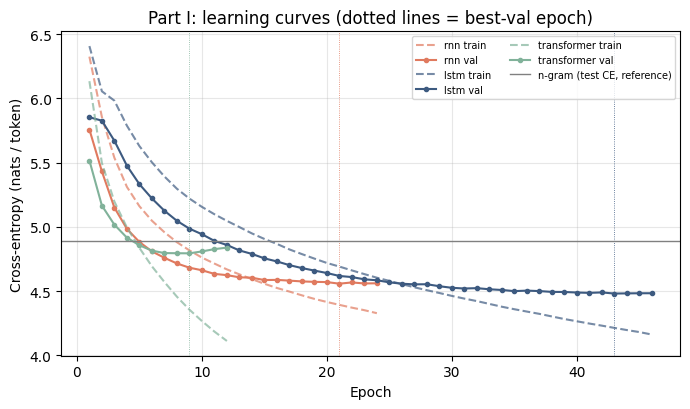

In [ ]:
# Training / validation loss curves
fig, ax = plt.subplots(figsize=(7, 4.2))
colors = {'rnn': '#E07A5F', 'lstm': '#3D5A80', 'transformer': '#81B29A'}
for k in ['rnn', 'lstm', 'transformer']:
    h = RESULTS[k]['history']; ep = range(1, len(h['val_loss']) + 1)
    ax.plot(ep, h['train_loss'], '--', color=colors[k], alpha=0.7, label=f'{k} train')
    ax.plot(ep, h['val_loss'], '-o', ms=3, color=colors[k], label=f'{k} val')
    ax.axvline(h['best_epoch'], color=colors[k], lw=0.6, ls=':')
ax.axhline(RESULTS['ngram']['test_ce'], color='grey', lw=1, label='n-gram (test CE, reference)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy (nats / token)')
ax.set_title('Part I: learning curves (dotted lines = best-val epoch)')
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_part1_loss.png', dpi=200); plt.show()

In [ ]:
#Generated text: same prompts, same decoding for every model
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[.,!?;:\"]")
def tokenize(t): return TOKEN_RE.findall(t.lower())
def encode(toks): return [stoi.get(t, UNK_ID) for t in toks]

PROMPTS = ["jo laughed and said",                      # character + dialogue
           "it was a cold winter morning and",         # narration
           "christmas won't be christmas without"]     # opening line of the book (train set) -> memorisation probe
GEN = dict(n_tokens=40, temperature=0.8, top_k=40, seed=SEED)   # matched decoding settings

def generate_ngram(m, prompt_ids, n_tokens, temperature, top_k, seed):
    g = torch.Generator().manual_seed(seed); ids = list(prompt_ids)
    for _ in range(n_tokens):
        p = m.dist(ids[-2] if len(ids) >= 2 else None, ids[-1])
        ids.append(sample_next(torch.log(torch.tensor(p)), temperature, top_k, [PAD_ID, UNK_ID], g))
    return ids[len(prompt_ids):]

generations = {}
for prompt in PROMPTS:
    pid = encode(tokenize(prompt))
    print('=' * 100, f'\nPROMPT: {prompt}')
    generations[prompt] = {}
    for k in ['ngram', 'rnn', 'lstm', 'transformer']:
        if k == 'ngram':
            out = generate_ngram(ngram, pid, **GEN)
        else:
            out = generate_neural(load_model(k), pid, GEN['n_tokens'], device, GEN['temperature'],
                                  GEN['top_k'], CFG['seq_len'], GEN['seed'])
        text = detok([itos[i] for i in out])
        generations[prompt][k] = text
        print(f'\n[{k:11s}] {text}')
json.dump({'settings': GEN, 'generations': generations}, open(f'{OUT}/part1_generations.json', 'w'), indent=1)

PROMPT: jo laughed and said

[ngram      ] , " returned amy, as the old fashioned pearls long for your own. a little girl, and i'm all, the girls were all her that she would, and amy were out of my things,

[rnn        ] , as she had no more than ever. " here's the old lady, and then it wasn't more than i can have a nice thing? " " and, i suppose you'd do you? " said

[lstm       ] , as she had got a pair of the family and amy in the middle of his own. " i'm all, it's a nice thing? " " i, dear, " said amy, wondering that

[transformer] her little, and amy began the story. " " amy, " said meg, who liked the instrument. " " " added meg? " " and, wondering amy, who took my word,
PROMPT: it was a cold winter morning and

[ngram      ] be very kind, and the next day. " " i knew you'd come. she had. jo was all, the girls were all her that she would, and amy were out of my things,

[rnn        ] when hannah came on his shoulders now. " that's a dozen thing, and i can't know. " " i, it's a nic